# 🍕 Exploratory Data Analysis with Open Food Facts

## A Hands-On Journey Through Real-World Food Data

---

**Welcome!** In this exercise, you'll become a data detective 🔍 exploring real food product data from around the world!

### What You'll Learn:
1. **Fetching data** from a real API
2. **Cleaning and exploring** data with Pandas
3. **Visualizing patterns** with Seaborn
4. **Sentiment Analysis** - teaching computers to understand emotions in text!

### Prerequisites:
- Basic Python syntax
- Control flow (if/else, loops)
- Functions
- Pandas & NumPy basics
- Matplotlib & Seaborn basics

---

**Let's get started!**

---
## Part 1: Setting Up Our Environment

First, let's import all the libraries we'll need.

In [1]:
# Core data libraries
import pandas as pd
import numpy as np

# Visualization libraries
import matplotlib.pyplot as plt
import seaborn as sns

# For fetching data from the internet
import requests

# For text processing and sentiment analysis
import re  # Regular expressions for text cleaning

# Set up nice-looking plots
plt.style.use('seaborn-v0_8-whitegrid')
sns.set_palette('husl')

# Make plots bigger and clearer
plt.rcParams['figure.figsize'] = [10, 6]
plt.rcParams['font.size'] = 12

# Ignore warnings for cleaner output
import warnings
warnings.filterwarnings('ignore')

print("All libraries imported successfully!")

All libraries imported successfully!


### 📦 Install Sentiment Analysis Library

We'll use **TextBlob** for sentiment analysis. It's beginner-friendly and works great!

In [10]:
# Install TextBlob if needed (uncomment the line below if you haven't installed it)


!pip install textblob

from textblob import TextBlob

print("TextBlob imported successfully!")

TextBlob imported successfully!


---
## Part 2: Fetching Data from the Open Food Facts API 🌐

**Open Food Facts** is a collaborative database of food products from around the world. It's like Wikipedia, but for food!

We'll fetch data using their API (Application Programming Interface). Think of an API as a waiter in a restaurant - you tell it what you want, and it brings you the data!

In [11]:
def fetch_food_data(search_term, page_size=100):

    # The API endpoint (URL where we request data)
    # Read more about the api from https://openfoodfacts.github.io/openfoodfacts-server/api/

    url = "https://world.openfoodfacts.org/cgi/search.pl"

    # Parameters for our search
    params = {
        'action': 'process',
        'search_terms': search_term,
        'page_size': page_size,
        'json': 'true',  # We want JSON format (easy to work with in Python)
        'fields': 'product_name,brands,categories,nutrition_grades,'
                  'nutriscore_score,nova_group,ingredients_text,'
                  'energy-kcal_100g,fat_100g,sugars_100g,proteins_100g,'
                  'salt_100g,countries_tags'
    }

    # Send the request
    print(f" Searching for '{search_term}' products...")
    response = requests.get(url, params=params)

    # Check if successful
    if response.status_code == 200:
        data = response.json()
        products = data.get('products', [])
        print(f"Found {len(products)} products!")
        return pd.DataFrame(products)
    else:
        print(f"Error: Could not fetch data (Status code: {response.status_code})")
        return pd.DataFrame()

### Let's Fetch Some Data!

We'll search for different types of food products to get a diverse dataset.

In [12]:
# Create a list of food category search terms to fetch data for
search_terms = ['chocolate', 'pizza', 'yogurt', 'chips', 'juice', 'cereal']

all_data = []

for term in search_terms:
    df_temp = fetch_food_data(term, page_size=50)
    df_temp['search_category'] = term
    all_data.append(df_temp)
df = pd.concat(all_data, ignore_index=True)

print(f"\n Total products collected: {len(df)}")

 Searching for 'chocolate' products...
Found 50 products!
 Searching for 'pizza' products...
Found 50 products!
 Searching for 'yogurt' products...
Found 50 products!
 Searching for 'chips' products...
Found 50 products!
 Searching for 'juice' products...
Found 50 products!
 Searching for 'cereal' products...
Found 50 products!

 Total products collected: 300


---
## Part 3: First Look at Our Data 👀

Before diving deep, let's understand what we're working with. This is the **"getting to know your data"** phase!

In [13]:
# See the first few rows
df.head()

,brands,categories,countries_tags,energy-kcal_100g,fat_100g,ingredients_text,nova_group,nutriscore_score,nutrition_grades,product_name,proteins_100g,salt_100g,sugars_100g,search_category
0,bimo,"Plant-based foods and beverages,Plant-based fo...",[en:morocco],504.0,22.2,"Coffret fourré au cacao (41,6%) et à la vanill...",2.0,28.0,e,Tonik,4.35,0.217,40.0,chocolate
1,J.D. Gross,"Snacks,Sweet snacks,Cocoa and its products,Cho...","[en:austria, en:belgium, en:bulgaria, en:eston...",600.0,48.0,"Pâte de cacao, cacao maigre en poudre, beurre ...",4.0,15.0,d,Chocolat noir - 85% cacao,12.00,0.000,12.0,chocolate
2,Ferrero,"Pequenos alomoços,Produtos para barrar,Doces p...","[en:czech-republic, en:denmark, en:estonia, en...",539.0,30.9,"Sugar, palm oil, _hazelnuts_ (13%), skimmed _m...",4.0,31.0,e,Nutella,6.30,0.107,56.3,chocolate
3,nutella,"Alimentos y bebidas de origen vegetal,Alimento...","[en:austria, en:belgium, en:bulgaria, en:franc...",539.0,30.9,"Sucre, huile de palme, _NOISETTES_ 13%, _LAIT_...",4.0,31.0,e,,6.30,0.107,56.3,chocolate
4,Maruja,"Snacks,Sweet snacks,Cocoa and its products,Con...","[en:algeria, en:cameroon, en:france, en:morocc...",539.0,33.0,"sugar, cocoa butter, whole milk powder, cocoa ...",4.0,31.0,e,,7.20,0.275,50.0,chocolate


In [ ]:
# Basic info about our dataset


Dataset Overview:
   • Number of products: 300
   • Number of columns: 14

 Column names:
   - brands
   - categories
   - countries_tags
   - energy-kcal_100g
   - fat_100g
   - ingredients_text
   - nova_group
   - nutriscore_score
   - nutrition_grades
   - product_name
   - proteins_100g
   - salt_100g
   - sugars_100g
   - search_category


In [ ]:
# Check data types and missing values


 Data types and missing values:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 300 entries, 0 to 299
Data columns (total 14 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   brands            297 non-null    object 
 1   categories        300 non-null    object 
 2   countries_tags    300 non-null    object 
 3   energy-kcal_100g  296 non-null    float64
 4   fat_100g          298 non-null    float64
 5   ingredients_text  297 non-null    object 
 6   nova_group        274 non-null    float64
 7   nutriscore_score  289 non-null    float64
 8   nutrition_grades  300 non-null    object 
 9   product_name      300 non-null    object 
 10  proteins_100g     297 non-null    float64
 11  salt_100g         295 non-null    float64
 12  sugars_100g       297 non-null    float64
 13  search_category   300 non-null    object 
dtypes: float64(7), object(7)
memory usage: 32.9+ KB


### 🧹 Quick Exercise: Count Missing Values

**Your turn!** Complete the code below to see what percentage of each column is missing.

In [ ]:
# TODO: Calculate missing value percentage for each column
# Hint: Use df.isnull().sum() to count nulls, then divide by len(df) and multiply by 100



 Missing Value Percentage by Column:
nova_group          8.7
nutriscore_score    3.7
salt_100g           1.7
energy-kcal_100g    1.3
ingredients_text    1.0
brands              1.0
sugars_100g         1.0
proteins_100g       1.0
fat_100g            0.7
categories          0.0
countries_tags      0.0
nutrition_grades    0.0
product_name        0.0
search_category     0.0
dtype: float64


---
## Part 4: Data Cleaning 🧹

Real-world data is messy! Let's clean it up before analyzing.

In [ ]:
# Create a clean copy of our data


# Rename columns to be more user-friendly
column_mapping = {
    'product_name': 'product_name',
    'brands': 'brand',
    'categories': 'categories',
    'nutrition_grades': 'nutrition_grade',
    'nutriscore_score': 'nutri_score',
    'nova_group': 'nova_group',
    'ingredients_text': 'ingredients',
    'energy-kcal_100g': 'calories_100g',
    'fat_100g': 'fat_100g',
    'sugars_100g': 'sugar_100g',
    'proteins_100g': 'protein_100g',
    'salt_100g': 'salt_100g',
    'countries_tags': 'countries'
}

# Only rename columns that exist in our data


print(" Columns renamed!")

 Columns renamed!


In [ ]:
# Show the updated columns


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 300 entries, 0 to 299
Data columns (total 14 columns):
 #   Column           Non-Null Count  Dtype  
---  ------           --------------  -----  
 0   brand            297 non-null    object 
 1   categories       300 non-null    object 
 2   countries        300 non-null    object 
 3   calories_100g    296 non-null    float64
 4   fat_100g         298 non-null    float64
 5   ingredients      297 non-null    object 
 6   nova_group       274 non-null    float64
 7   nutri_score      289 non-null    float64
 8   nutrition_grade  300 non-null    object 
 9   product_name     300 non-null    object 
 10  protein_100g     297 non-null    float64
 11  salt_100g        295 non-null    float64
 12  sugar_100g       297 non-null    float64
 13  search_category  300 non-null    object 
dtypes: float64(7), object(7)
memory usage: 32.9+ KB


In [ ]:
# Remove products without a name (can't analyze nameless products!)


Products before cleaning: 300
Products after removing nameless ones: 296


In [ ]:
# Convert nutrition grade to uppercase (standardize)


# Remove duplicates based on product name


Removed 22 duplicate products

 Final dataset: 274 unique products


---
## Part 5: Exploratory Data Analysis (EDA) 📊

Now for the fun part! Let's explore patterns and insights in our data.

### 5.1 Nutrition Grades Distribution

The **Nutri-Score** rates products from A (healthiest) to E (least healthy). Let's see the distribution!

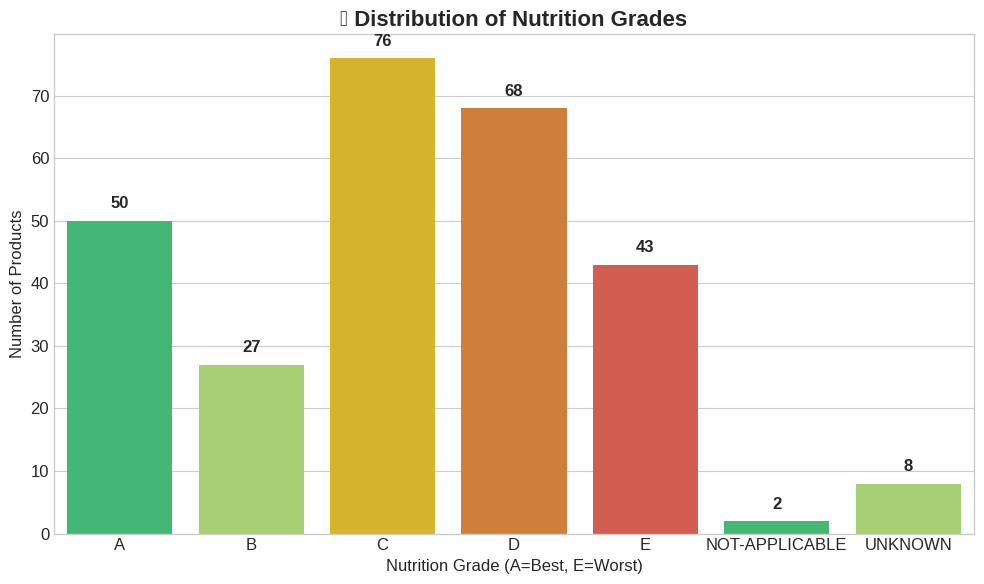


💡 Insights:
   • Most common grade: C (76 products)
   • Healthy products (A or B): 77 (28.1%)


In [ ]:
# Count nutrition grades


    # Create a colorful bar chart


    # Print insights


### 5.2 Comparing Nutrition Across Food Categories

Which food categories are healthier? Let's compare!

<Figure size 1200x600 with 0 Axes>

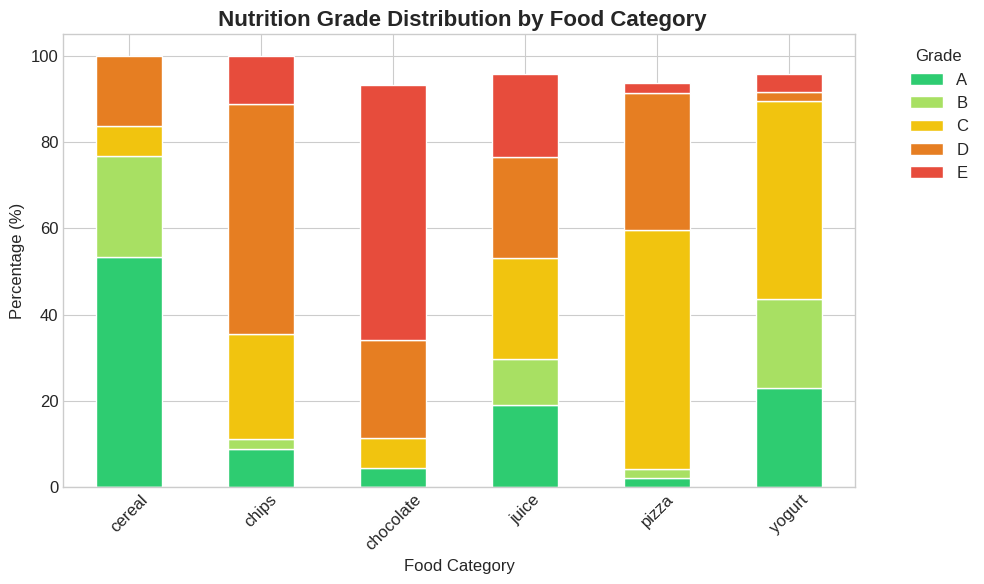

In [ ]:
# Compare nutrition grades by search category


    # Create a crosstab for stacked bar chart


    # Reorder columns A to E


    # Plot


### 5.3 Nutritional Content Analysis

Let's analyze the actual nutritional values (calories, sugar, fat, etc.)

In [ ]:
# Get statistics for nutritional columns


Nutritional Statistics (per 100g):
       calories_100g  fat_100g  sugar_100g  protein_100g  salt_100g
count         271.00    273.00      272.00        272.00     270.00
mean          275.51     12.08       10.12          6.66       0.58
std           189.39     13.69       14.70          4.77       0.66
min             0.30      0.00        0.00          0.00       0.00
25%            75.15      1.50        2.40          3.32       0.03
50%           251.00      7.10        4.20          6.70       0.25
75%           460.00     20.30       10.00          9.83       0.98
max           627.00     80.00       79.90         46.00       4.00


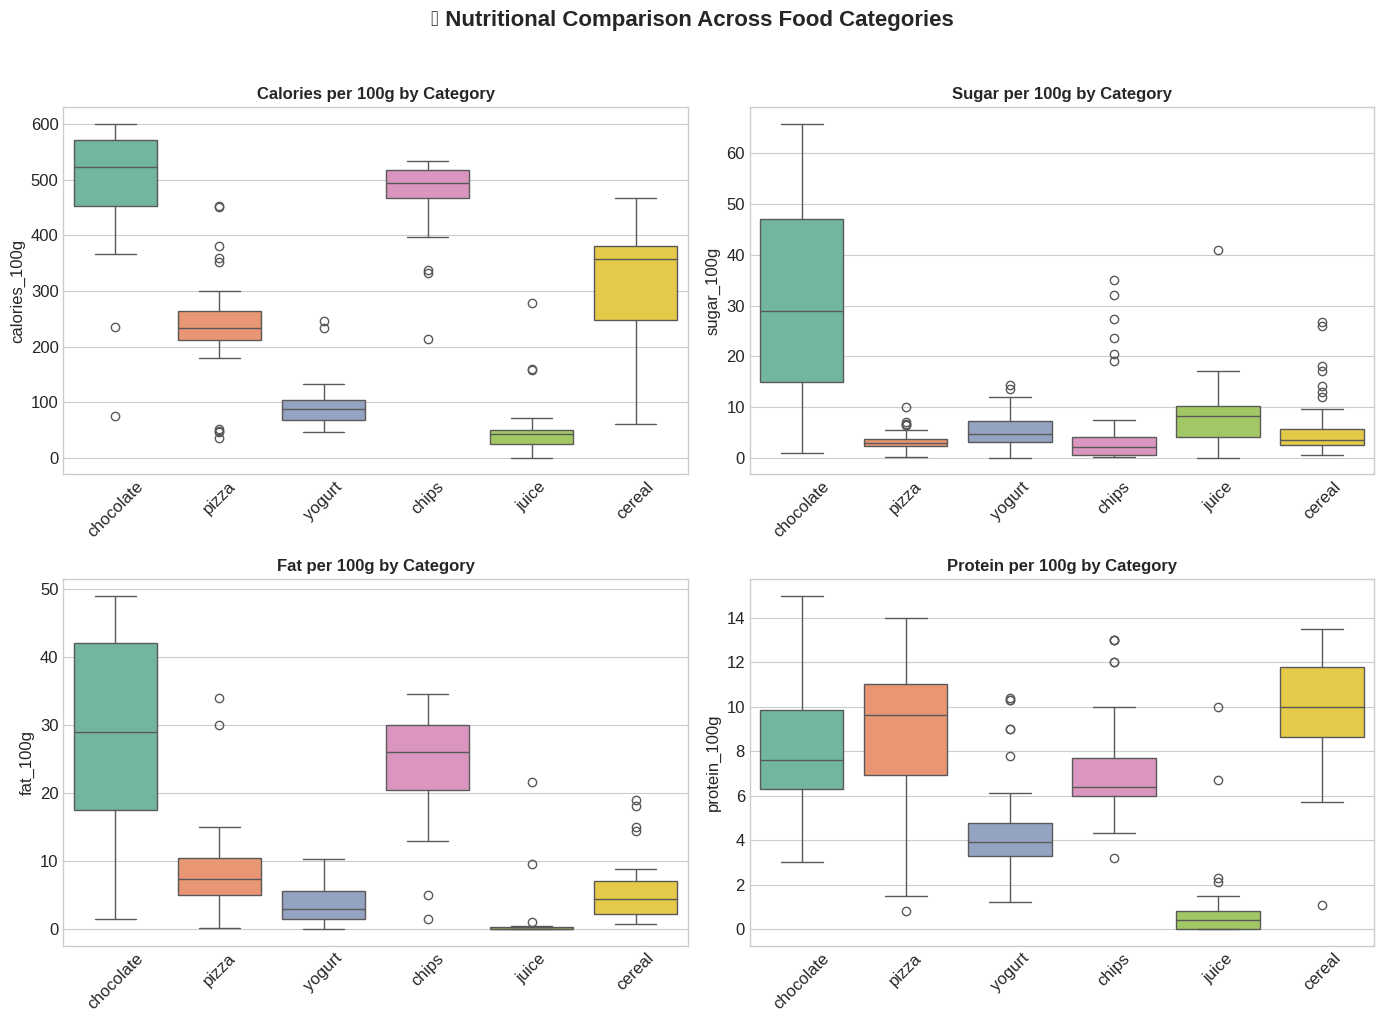

In [ ]:
# Create box plots for nutritional values by category


### 5.4 Correlation Heatmap

Let's see how different nutritional values relate to each other. Do high-sugar foods also tend to be high in fat?

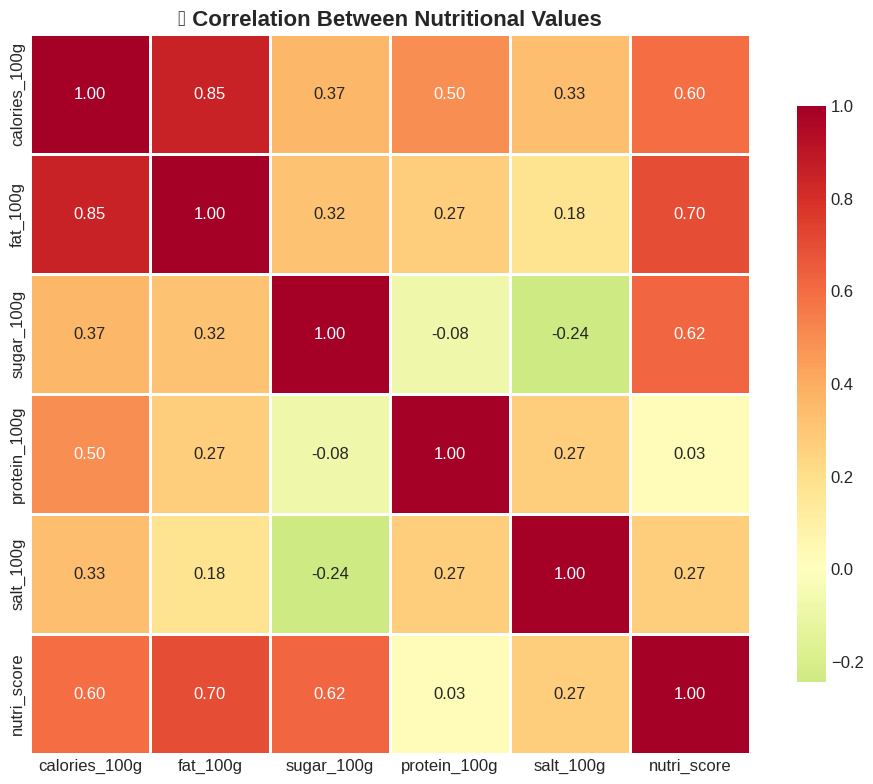


💡 How to read this:
   • Values close to 1 (red): Strong positive relationship
   • Values close to -1 (green): Strong negative relationship
   • Values close to 0 (yellow): No relationship


In [ ]:
# Create correlation matrix


    # Create heatmap


### 5.5 🎯 Exercise: Create Your Own Visualization!

**Your turn!** Create a scatter plot showing the relationship between sugar and calories.

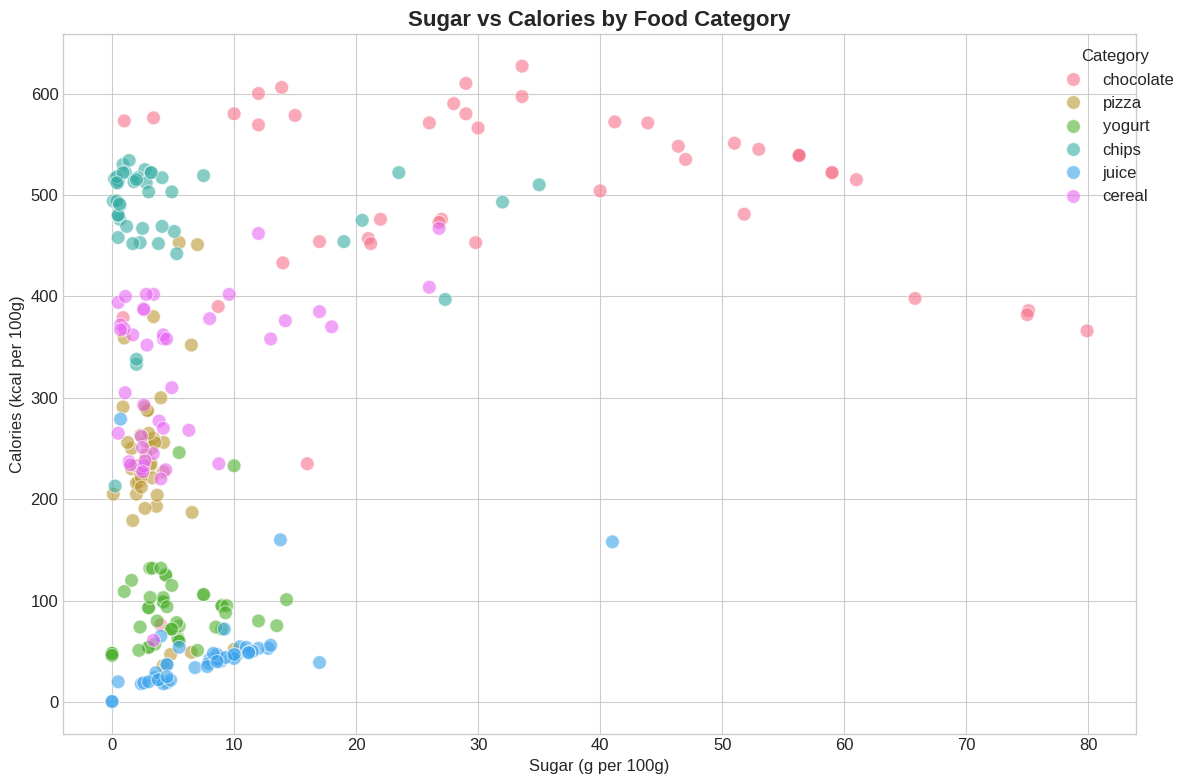

In [ ]:
# TODO: Create a scatter plot
# Requirements:
# 1. X-axis: sugar_100g
# 2. Y-axis: calories_100g
# 3. Color the points by 'search_category'
# 4. Add a title and labels

# Hint: Use sns.scatterplot()

if 'sugar_100g' in df_clean.columns and 'calories_100g' in df_clean.columns:
    plt.figure(figsize=(12, 8))

    # Filter out missing values and extreme outliers
    plot_data = df_clean.dropna(subset=['sugar_100g', 'calories_100g'])
    plot_data = plot_data[plot_data['calories_100g'] < 1000]  # Remove extreme outliers

    # YOUR CODE HERE:


---
## Part 6: Sentiment Analysis

Now for something exciting! **Sentiment Analysis** is teaching computers to understand emotions in text.

We'll analyze the **product names and ingredients** to see if there are interesting patterns in how products are named!

### 6.1 What is Sentiment Analysis?

Sentiment analysis measures:
- **Polarity**: How positive or negative the text is (-1 to +1)
- **Subjectivity**: How opinion-based vs factual the text is (0 to 1)

Let's see some examples!

In [15]:
# Example: How sentiment analysis works
examples = [
    "This is absolutely delicious and amazing!",
    "Tastes terrible and awful",
    "Premium organic dark chocolate",
    "Cheap processed food product",
    "Natural wholesome ingredients"
]

print("Sentiment Analysis Examples:")
print("-" * 70)


for text in examples:
  blob = TextBlob(text)
  polarity = round(blob.sentiment.polarity, 2)
  subjectivity = round(blob.sentiment.subjectivity, 2)
  if polarity > 0.1:
    sentiment = "😀Positive"
  elif polarity < -0.1:
    sentiment = "Negative"
  else:
    sentiment = "Neutral"
  print(f"Text: {text}")
  print(f"Sentiment: {sentiment} (Polarity: {polarity}, Subjectivity: {subjectivity})")

Sentiment Analysis Examples:
----------------------------------------------------------------------
Text: This is absolutely delicious and amazing!
Sentiment: 😀Positive (Polarity: 0.88, Subjectivity: 0.95)
Text: Tastes terrible and awful
Sentiment: Negative (Polarity: -1.0, Subjectivity: 1.0)
Text: Premium organic dark chocolate
Sentiment: Negative (Polarity: -0.15, Subjectivity: 0.4)
Text: Cheap processed food product
Sentiment: 😀Positive (Polarity: 0.4, Subjectivity: 0.7)
Text: Natural wholesome ingredients
Sentiment: Neutral (Polarity: 0.1, Subjectivity: 0.4)


### 6.2 Analyzing Product Names

Let's apply sentiment analysis to our food product names!

In [23]:
def analyze_sentiment(text):
  if pd.isna(text) or text =='':
    return (0, 0, 'Únknown')

  blob = TextBlob(text)
  polarity = round(blob.sentiment.polarity, 2)
  subjectivity = round(blob.sentiment.subjectivity, 2)
  if polarity > 0.1:
    sentiment = "😀Positive"
  elif polarity < -0.1:
    sentiment = "Negative"
  else:
    sentiment = "Neutral"
  return (polarity, subjectivity, sentiment)



In [24]:
df.head()

,brands,categories,countries_tags,energy-kcal_100g,fat_100g,ingredients_text,nova_group,nutriscore_score,nutrition_grades,product_name,proteins_100g,salt_100g,sugars_100g,search_category
0,bimo,"Plant-based foods and beverages,Plant-based fo...",[en:morocco],504.0,22.2,"Coffret fourré au cacao (41,6%) et à la vanill...",2.0,28.0,e,Tonik,4.35,0.217,40.0,chocolate
1,J.D. Gross,"Snacks,Sweet snacks,Cocoa and its products,Cho...","[en:austria, en:belgium, en:bulgaria, en:eston...",600.0,48.0,"Pâte de cacao, cacao maigre en poudre, beurre ...",4.0,15.0,d,Chocolat noir - 85% cacao,12.00,0.000,12.0,chocolate
2,Ferrero,"Pequenos alomoços,Produtos para barrar,Doces p...","[en:czech-republic, en:denmark, en:estonia, en...",539.0,30.9,"Sugar, palm oil, _hazelnuts_ (13%), skimmed _m...",4.0,31.0,e,Nutella,6.30,0.107,56.3,chocolate
3,nutella,"Alimentos y bebidas de origen vegetal,Alimento...","[en:austria, en:belgium, en:bulgaria, en:franc...",539.0,30.9,"Sucre, huile de palme, _NOISETTES_ 13%, _LAIT_...",4.0,31.0,e,,6.30,0.107,56.3,chocolate
4,Maruja,"Snacks,Sweet snacks,Cocoa and its products,Con...","[en:algeria, en:cameroon, en:france, en:morocc...",539.0,33.0,"sugar, cocoa butter, whole milk powder, cocoa ...",4.0,31.0,e,,7.20,0.275,50.0,chocolate


In [27]:
# Apply sentiment analysis to product names
print("Applying sentiment analysis to product names...")

df['name_sentiment'] = df['product_name'].apply(analyze_sentiment)

# Extract individual components
df['name_polarity'] = df['name_sentiment'].apply(lambda x: x[0])
df['name_subjectivity'] = df['name_sentiment'].apply(lambda x: x[1])
df['name_sentiment'] = df['name_sentiment'].apply(lambda x: x[2])

print("Sentiment analysis complete!")


Applying sentiment analysis to product names...
Sentiment analysis complete!


In [29]:
# View some examples
print("📝 Sample Product Names with Sentiment:")
print("="*80)

sample = df[["product_name", "name_polarity", "name_subjectivity", "name_sentiment"]].sample(50)
sample

📝 Sample Product Names with Sentiment:


,product_name,name_polarity,name_subjectivity,name_sentiment
43,nutella,0.00,0.00,Neutral
162,Chips de lentilles saveur fines herbes,0.00,0.00,Neutral
1,Chocolat noir - 85% cacao,0.00,0.00,Neutral
234,Innocent Smooth Orange Juice,0.45,0.60,😀Positive
40,Le Choco,0.00,0.00,Neutral
202,Press up,0.00,0.00,Neutral
128,Greek style natural yoghurt,0.05,0.20,Neutral
11,1848 Chocolat en poudre,0.00,0.00,Neutral
206,Coca-Cola Zero,0.00,0.00,Neutral
154,Sour Cream & Onion,-0.15,0.10,Negative


### 6.3 Visualizing Product Name Sentiments

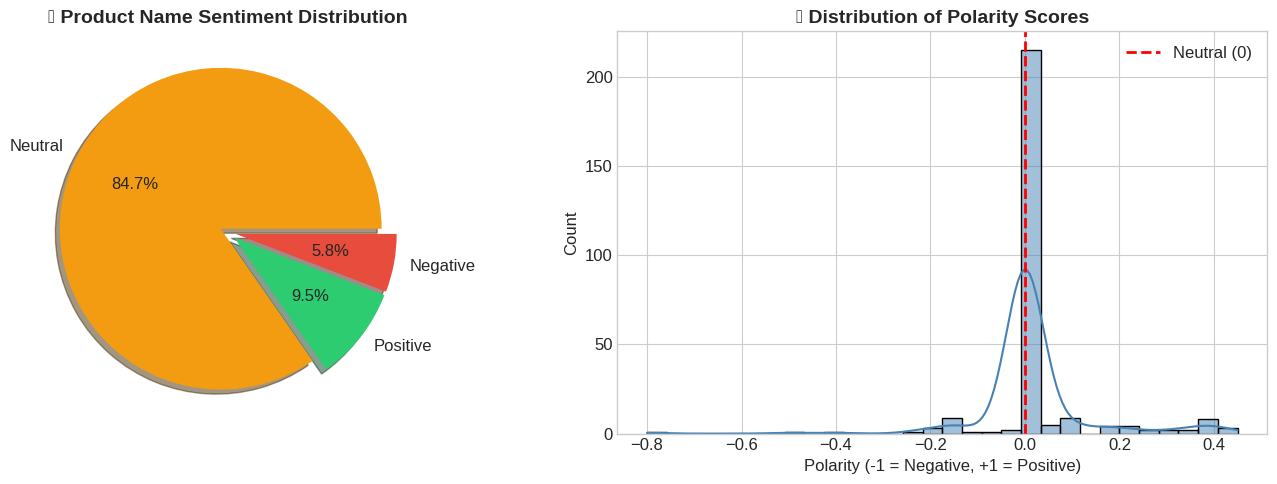

In [ ]:
# Distribution of sentiment labels

# Plot 1: Sentiment Distribution (Pie Chart)


# Plot 2: Polarity Distribution (Histogram)


### 6.4 Do Healthier Products Have More Positive Names?

**Interesting question!** Let's see if there's a relationship between nutrition grade and product name sentiment.

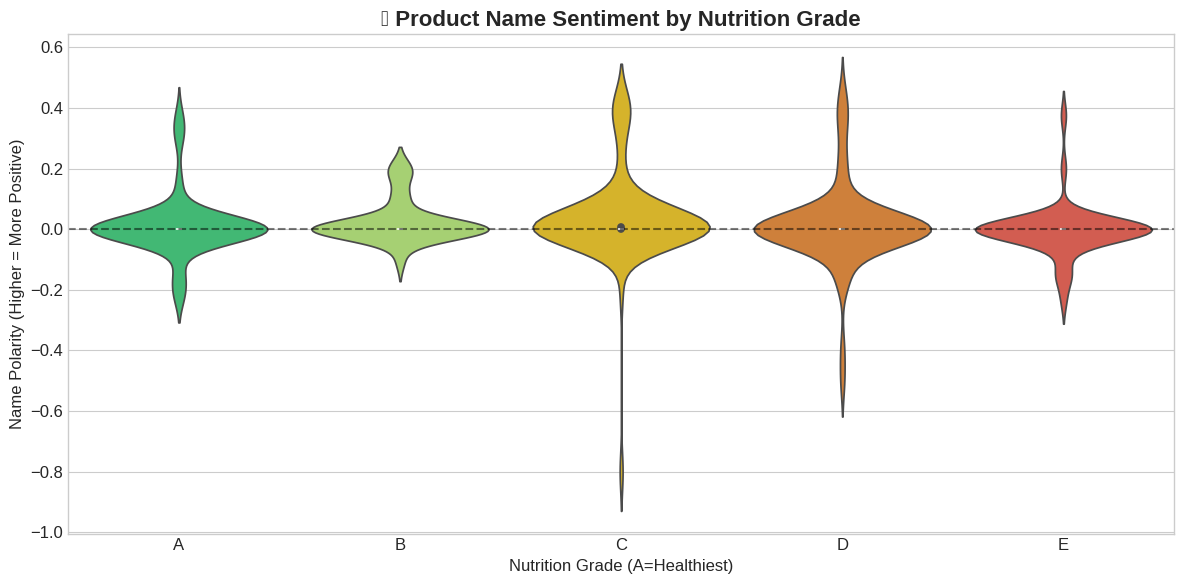


📊 Average Name Polarity by Nutrition Grade:
   Grade A: 0.011
   Grade B: 0.025
   Grade C: 0.036
   Grade D: 0.012
   Grade E: -0.005


In [ ]:
# Compare sentiment by nutrition grade


    # Filter out unknown grades and sentiments

    # Create violin plot


    # Calculate average polarity by grade


### 6.5 Sentiment by Food Category

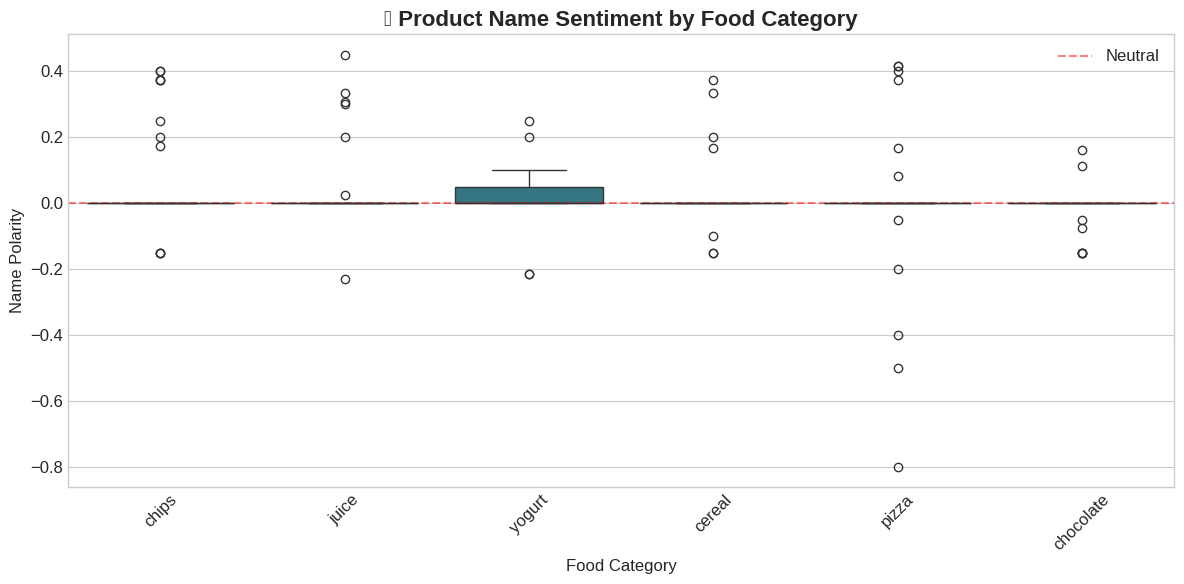


📊 Average Name Sentiment by Category (sorted by positivity):
   😐 Chips: 0.047
   😐 Juice: 0.029
   😐 Yogurt: 0.020
   😐 Cereal: 0.016
   😐 Pizza: -0.002
   😐 Chocolate: -0.010


In [ ]:
# Compare sentiment across food categories
plt.figure(figsize=(12, 6))

# Box plot of polarity by category
category_order = df_clean.groupby('search_category')['name_polarity'].mean().sort_values(ascending=False).index

sns.boxplot(data=df_clean, x='search_category', y='name_polarity',
            order=category_order, palette='viridis')





# Print average sentiment by category
print("Average Name Sentiment by Category (sorted by positivity):")
avg_by_cat = df_clean.groupby('search_category')['name_polarity'].mean().sort_values(ascending=False)





### 6.6 Finding the Most Positive and Negative Product Names

In [ ]:
# Most positive product names
print("😊 TOP 10 MOST POSITIVE PRODUCT NAMES:")
print("="*60)
top_positive = df_clean.nlargest(10, 'name_polarity')[['product_name', 'name_polarity', 'search_category']]



😊 TOP 10 MOST POSITIVE PRODUCT NAMES:
1. Innocent Smooth Orange Juice...
   Category: juice | Polarity: 0.45

2. HERTA Pâte à Pizza Fine et Rectangulaire 390g...
   Category: pizza | Polarity: 0.42

3. HERTA Pâte à Pizza Fine et Ronde 265g...
   Category: pizza | Polarity: 0.42

4. house light dressing...
   Category: pizza | Polarity: 0.40

5. Lightly sea salted crisps...
   Category: chips | Polarity: 0.40

6. Lightly Salted Potato chips...
   Category: chips | Polarity: 0.40

7. Pizza dough original...
   Category: pizza | Polarity: 0.38

8. Pringles Original...
   Category: chips | Polarity: 0.38

9. cooky original chocolate chips...
   Category: chips | Polarity: 0.38

10. Tortilla Nachips Original...
   Category: chips | Polarity: 0.38



In [ ]:
# Most negative product names
print("😟 TOP 10 MOST NEGATIVE PRODUCT NAMES:")
print("="*60)
top_negative = df_clean.nsmallest(10, 'name_polarity')[['product_name', 'name_polarity', 'search_category']]


😟 TOP 10 MOST NEGATIVE PRODUCT NAMES:
1. Pizza Base with Tomato Sauce...
   Category: pizza | Polarity: -0.80

2. Pizza Crust Cheesy 4 fromages...
   Category: pizza | Polarity: -0.50

3. Stonebaked Thin Margherita Pizza...
   Category: pizza | Polarity: -0.40

4. Raw Boost...
   Category: juice | Polarity: -0.23

5. Alpro Plain...
   Category: yogurt | Polarity: -0.21

6. Plant soya pot plain...
   Category: yogurt | Polarity: -0.21

7. Gluten Free Pizza Base 2 x (300g)...
   Category: pizza | Polarity: -0.20

8. Sour Cream & Onion...
   Category: chips | Polarity: -0.15

9. Pringles sour cream...
   Category: chips | Polarity: -0.15

10. Organic 70% Dark Chocolate Bar...
   Category: chocolate | Polarity: -0.15



### 6.7  Exercise: Analyze Ingredient Sentiment

**Your turn!** Apply sentiment analysis to the ingredients text and see what patterns emerge!

 Analyzing sentiment of ingredients...


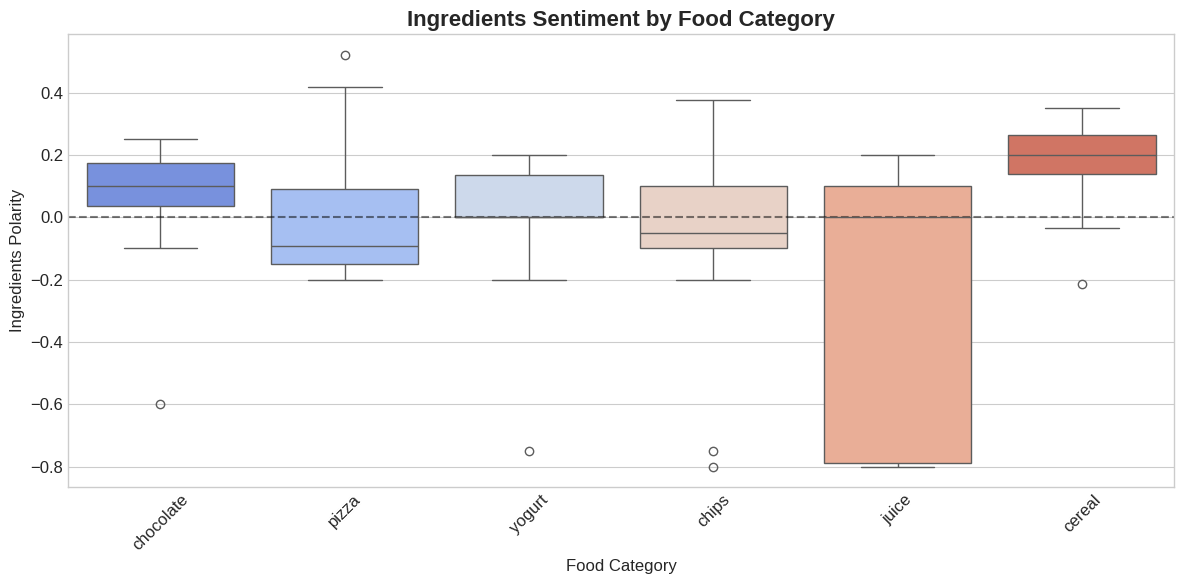

Great job! You've successfully analyzed ingredient sentiments!


In [ ]:
# TODO: Apply sentiment analysis to ingredients
# 1. Apply the analyze_sentiment function to the 'ingredients' column
# 2. Create a new column called 'ingredients_polarity'
# 3. Create a visualization comparing ingredient sentiment across categories

if 'ingredients' in df_clean.columns:
    # Apply sentiment analysis to ingredients
    print(" Analyzing sentiment of ingredients...")
    df_clean['ingredients_sentiment'] = df_clean['ingredients'].apply(analyze_sentiment)
    df_clean['ingredients_polarity'] = df_clean['ingredients_sentiment'].apply(lambda x: x[0])

    # Create visualization


    # Filter products with ingredients



---
## Part 7: Key Insights & Summary 📝

Let's summarize what we've discovered!

In [ ]:
# Generate a summary report
print("="*70)
print("EXPLORATORY DATA ANALYSIS SUMMARY")
print("="*70)

print(f" Dataset Overview:")
print(f"   • Total unique products analyzed: {len(df_clean)}")
print(f"   • Food categories explored: {', '.join(df_clean['search_category'].unique())}")

if 'nutrition_grade' in df_clean.columns:
    grade_dist = df_clean['nutrition_grade'].value_counts(normalize=True) * 100
    print(f" Nutrition Grades:")
    for grade in ['A', 'B', 'C', 'D', 'E']:
        if grade in grade_dist:
            print(f"   • Grade {grade}: {grade_dist[grade]:.1f}%")

### Continue with the rest i.e produce the rest of the table below.

EXPLORATORY DATA ANALYSIS SUMMARY
 Dataset Overview:
   • Total unique products analyzed: 274
   • Food categories explored: chocolate, pizza, yogurt, chips, juice, cereal
 Nutrition Grades:
   • Grade A: 18.2%
   • Grade B: 9.9%
   • Grade C: 27.7%
   • Grade D: 24.8%
   • Grade E: 15.7%
Sentiment Analysis Results:
   • Positive names: 9.5%
   • Neutral names: 84.7%
   • Negative names: 5.8%
Average name polarity: 0.017
 Key Findings:
   • Most positive product names: Chips category
   • Highest average sugar content: Chocolate category

